# Function 4 - Week 5: Model Predictions

#### Model Predictions using Official Observations up to and including Week 4 return, received on **23 October 2026**.

In [1]:
# Imports and shared helpers.
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
from IPython.display import display

shared_dir = next(
    (folder / "Shared" for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "Shared" / "model_review_helpers.py").is_file()), None,
)
if shared_dir is None:
    raise FileNotFoundError("Run from this notebook's folder inside notebooks/.")
if str(shared_dir) not in sys.path:
    sys.path.insert(0, str(shared_dir))

from exploration_review_helpers import load_exploration_review
from model_review_helpers import (
    make_regression_models, fit_model_review, review_latest_predictions,
    build_review_candidates, score_review_candidates,
    query_prediction, weight_sensitivity,
)
from model_review_plots import plot_held_out_comparison, plot_latest_predictions
from coverage_cache import compare_coverage_batches
from query_budget import remaining_queries
from plot_helpers import PLOT_CONFIG
from model_review_plots import plot_coordinate_model_review

In [2]:
# Settings for this run. Keep model assumptions and search settings here.
FUNCTION_NUMBER = 4
CURRENT_WEEK = 5
INPUT_COLUMNS = ["x1", "x2", "x3", "x4"]
OUTPUT_COLUMN = "y"
EXPECTED_ROUND_COUNTS = {0: 30, 1: 1, 2: 1, 3: 1, 4: 1}
ANALYSIS_DIR = Path.cwd().resolve()
WEEK_DIR = ANALYSIS_DIR.parent
DATA_PATH = ANALYSIS_DIR / "observations.csv"
FIGURES_DIR = ANALYSIS_DIR / "figures"
TITLE = f"Function {FUNCTION_NUMBER} - Week {CURRENT_WEEK}"
PORTAL_DECIMALS = 6
MODEL_NAMES = ["Mean baseline", "Linear regression", "Ridge", "Kernel ridge", "Gaussian process"]
GP_NAMES = ["Gaussian process"]
# Retain the existing GP diagonal regularisation; it is not a measured noise level.
MODEL_SETTINGS = dict(
    noise_fraction=0.10, ridge_alpha=1.0,
    kernel_ridge_alpha=0.1, kernel_ridge_gamma=1.0,
    length_scale=0.3, length_scale_bounds=(0.03, 2.0),
    amplitude=1.0, amplitude_bounds=(0.01, 100.0), optimiser_restarts=3, seed=42,
)
EXPLORATION_WEIGHT = 1.96
SEARCH_SETTINGS = dict(
    broad_power=14, broad_seed=42, local_power=12, local_seed=43,
    local_radius=0.15, precision=PORTAL_DECIMALS, include_corners=True,
)
COVERAGE_SETTINGS = dict(
    max_queries=1, optimization_power=12, evaluation_power=15,
    optimization_seed=42, evaluation_seed=43, comparison_seed=42, verbose=False,
)
EXPLORATION_WEIGHTS = (0.0, 1.0, 1.96, 3.0)
VALIDATION_MODELS = ["Ridge", "Kernel ridge"]
COORDINATE_VIEW_SETTINGS = dict(side=250, padding_fraction=0.05, figsize=(16, 4.6))
CANDIDATES_TO_SHOW = 5
VALIDATION_SIZE = (15, 5)
LATEST_RESULT_SIZE = (11, 5.5)

In [3]:
# Validate the same snapshot used by the exploration review.
review = load_exploration_review(
    DATA_PATH, input_columns=INPUT_COLUMNS, output_column=OUTPUT_COLUMN,
    expected_round_counts=EXPECTED_ROUND_COUNTS,
)
inputs = review["inputs"].to_numpy(dtype=float)
raw_y = review["outputs"].to_numpy(dtype=float)
anchor = inputs[int(np.argmax(raw_y))].copy()
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
display(review["latest_submissions"].drop(columns="comparison"))

,observation_id,source_round,x1,x2,x3,x4,y,output_rank
33,round-04,4,0.354513,0.376712,0.37896,0.488593,-1.25916,3


In [4]:
# Fit each complete estimator within every held-out fold.
models = make_regression_models(len(INPUT_COLUMNS), **MODEL_SETTINGS)
models = {name: models[name] for name in MODEL_NAMES}
model_run = fit_model_review(models, inputs, raw_y, gp_names=GP_NAMES)
selected_model = model_run["selected_model"]
modelled_axes = tuple(range(len(INPUT_COLUMNS)))
display(model_run["table"].round(6))
display(pd.Series({"Selected GP": model_run["selected_name"], "Fitted kernel": model_run["fitted_kernel"]}))

,Model,Training MAE,LOO MAE,LOO RMSE,MAE / baseline,RMSE reduction (%)
0,Gaussian process,0.161589,0.988323,1.466791,0.146681,83.051247
1,Kernel ridge,1.960129,3.532399,4.444830,0.524259,48.640030
2,Ridge,5.047574,5.641139,6.856622,0.837227,20.771792
3,Linear regression,5.045798,5.878846,6.979268,0.872506,19.354614
4,Mean baseline,6.539714,6.737888,8.654269,1.000000,0.000000


Selected GP                      Gaussian process
Fitted kernel    1.79**2 * RBF(length_scale=0.71)
dtype: str

,Model,Latest held-out prediction,Latest error,Latest absolute error (%),Latest share of squared error (%),Other rows LOO RMSE
0,Gaussian process,-1.2420,0.0171,1.3589,0.0004,1.4888
1,Kernel ridge,-5.6554,-4.3963,349.1433,2.8773,4.4463
2,Linear regression,-13.2182,-11.9590,949.7605,8.6356,6.7714
3,Ridge,-13.7220,-12.4628,989.7743,9.7171,6.6130
4,Mean baseline,-15.7689,-14.5097,1152.3345,8.2676,8.4135


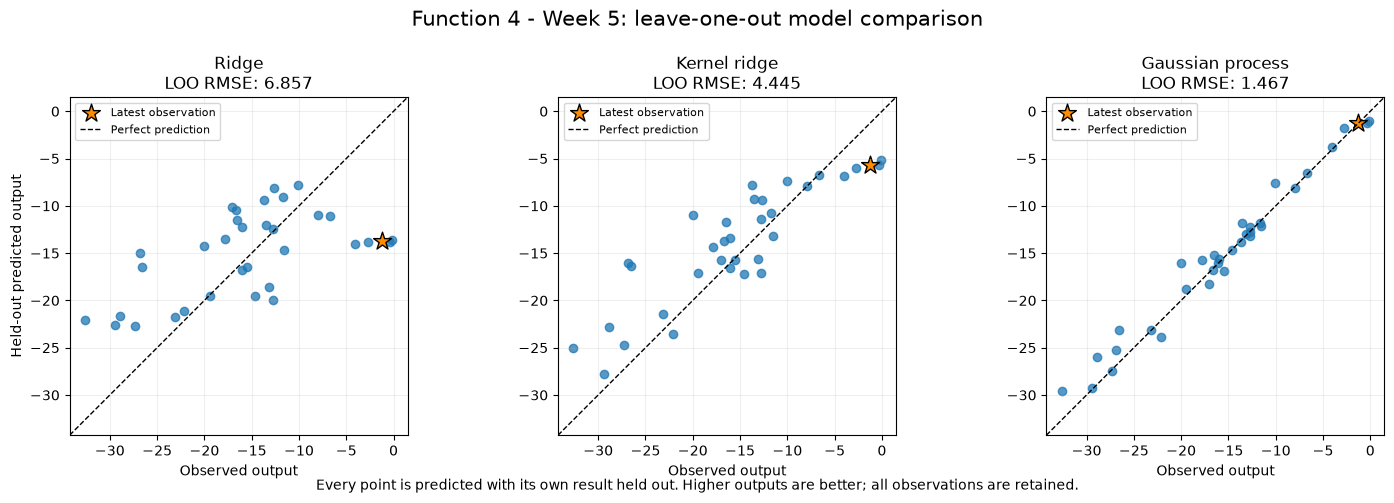

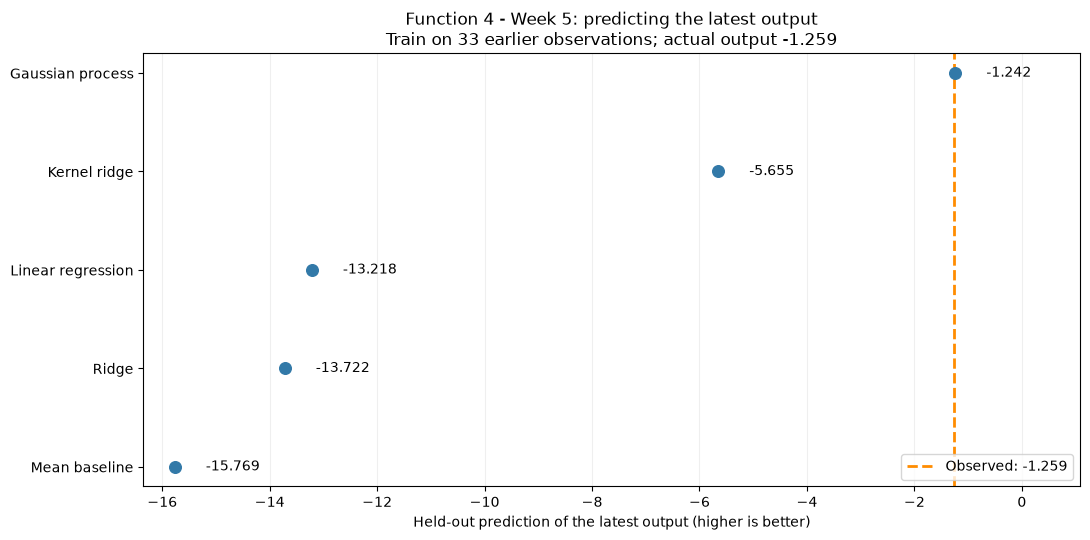

In [5]:
# This checks the latest held-out result retrospectively; it is not a saved forecast.
latest_review = review_latest_predictions(model_run["predictions"], raw_y, review["latest_mask"])
latest_output = float(raw_y[review["latest_mask"]][0])
display(latest_review.round(4))
display(plot_held_out_comparison(
    model_run["predictions"], raw_y,
    model_names=[*VALIDATION_MODELS, model_run["selected_name"]], latest_mask=review["latest_mask"],
    title=f"{TITLE}: leave-one-out model comparison", figsize=VALIDATION_SIZE,
    save_to=FIGURES_DIR / "model-comparison-validation.png",
))
display(plot_latest_predictions(
    latest_review, latest_output, n_training_rows=int((~review["latest_mask"]).sum()),
    title=f"{TITLE}: predicting the latest output", figsize=LATEST_RESULT_SIZE,
    save_to=FIGURES_DIR / "latest-output-predictions.png",
))

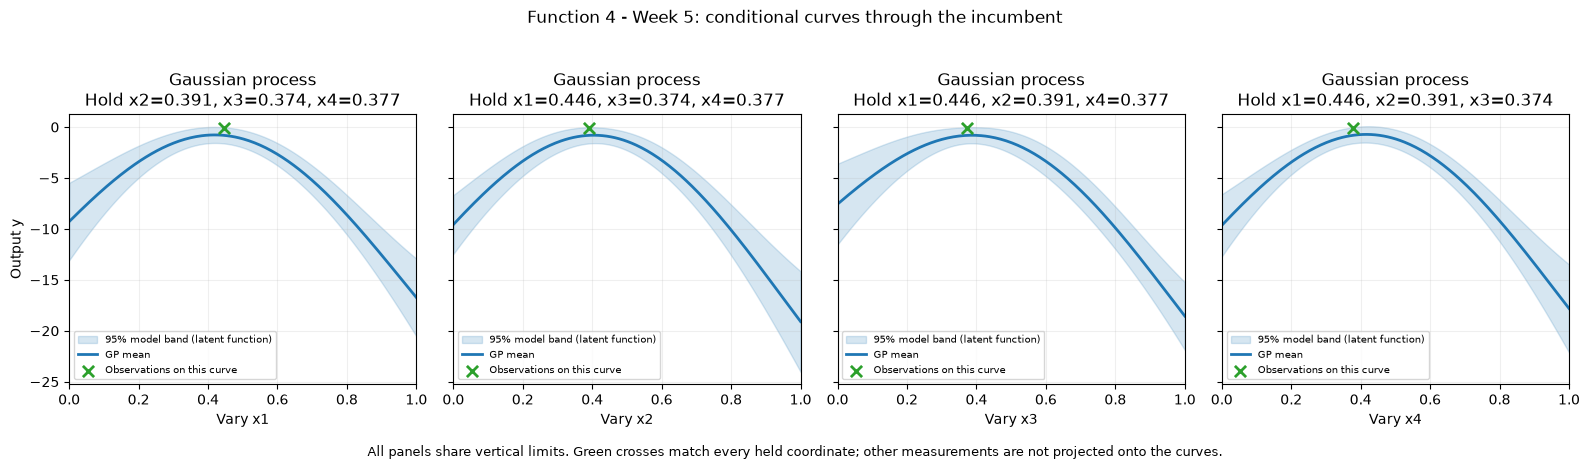

In [6]:
# Vary one coordinate at a time through the measured incumbent, holding all others fixed.
plot_coordinate_model_review(
    {name: model_run["fitted"][name] for name in GP_NAMES}, inputs, raw_y, anchor,
    input_columns=INPUT_COLUMNS, title=f"{TITLE}: conditional curves through the incumbent",
    **COORDINATE_VIEW_SETTINGS, save_to=FIGURES_DIR / "gp-coordinate-slices.png",
)

In [7]:
# Reuse the geometric coverage cache, then score the exact rounded candidate inputs.
coverage = compare_coverage_batches(
    existing=inputs, cache_dir=ANALYSIS_DIR / ".coverage-cache", **COVERAGE_SETTINGS,
)
candidates = build_review_candidates(
    inputs, anchor, coverage["proposed_batches"][1], input_columns=INPUT_COLUMNS, **SEARCH_SETTINGS,
)
scored = score_review_candidates(
    selected_model, candidates, input_columns=INPUT_COLUMNS,
    weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
by_source = scored.loc[scored.groupby("candidate_source")["ucb"].idxmax()].sort_values("ucb", ascending=False)
display(by_source.round(6))
display(pd.DataFrame(coverage["results"]))

,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,candidate_source
0,0.414390,0.395070,0.420904,0.438653,-0.756502,0.456939,0.139098,Near incumbent
23,0.445683,0.395023,0.413569,0.454466,-0.842012,0.443766,0.027771,Full input space
14209,0.791460,0.031242,0.706787,0.678378,-20.819469,3.174379,-14.597686,Single coverage query


,q,max_distance,p95_distance
0,0,0.663919,0.446355
1,1,0.663919,0.436408


In [8]:
# Every coordinate remains free in the rounded candidate comparison.
recommended = scored.iloc[0]
next_query = recommended[INPUT_COLUMNS].to_numpy(dtype=float)
proposal = query_prediction(
    selected_model, next_query, inputs, raw_y, weight=EXPLORATION_WEIGHT, precision=PORTAL_DECIMALS,
)
proposal_source = recommended.candidate_source
display(pd.Series(proposal))

point                         [0.41439, 0.39507, 0.420904, 0.438653]
predicted_output                                           -0.756502
posterior_std                                               0.456939
ucb                                                         0.139098
predicted_mean_improvement                                 -0.626584
inside_sampled_hull                                             True
portal_input                     0.414390-0.395070-0.420904-0.438653
dtype: object

In [9]:
# Reuse the same candidate pool and predictions while changing the exploration weight.
exploration_sensitivity = weight_sensitivity(
    scored, inputs, input_columns=INPUT_COLUMNS, modelled_axes=modelled_axes,
    weights=EXPLORATION_WEIGHTS, precision=PORTAL_DECIMALS,
)
display(exploration_sensitivity.round(6))

,Weight,x1,x2,x3,x4,Predicted output,Posterior SD
0,0.00,0.435387,0.397278,0.381715,0.389299,-0.724998,0.398992
1,1.00,0.414390,0.395070,0.420904,0.438653,-0.756502,0.456939
2,1.96,0.414390,0.395070,0.420904,0.438653,-0.756502,0.456939
3,3.00,0.382653,0.408292,0.445403,0.446992,-0.963343,0.536055


In [10]:
# Retain every coordinate in the alternatives; these predictions are not measured outputs.
display(scored.head(CANDIDATES_TO_SHOW)[[
    *INPUT_COLUMNS, "posterior_mean", "posterior_sd", "ucb", "candidate_source",
]].round(PORTAL_DECIMALS))

,x1,x2,x3,x4,posterior_mean,posterior_sd,ucb,candidate_source
0,0.414390,0.395070,0.420904,0.438653,-0.756502,0.456939,0.139098,Near incumbent
1,0.396078,0.425169,0.399186,0.435808,-0.741509,0.441149,0.123143,Near incumbent
2,0.390908,0.428850,0.416922,0.399788,-0.795420,0.455974,0.098289,Near incumbent
3,0.365410,0.410434,0.404118,0.411723,-0.831396,0.469300,0.088432,Near incumbent
4,0.382653,0.408292,0.445403,0.446992,-0.963343,0.536055,0.087324,Near incumbent


In [11]:
# Preserve the saved summary contract read by the separate cohort comparison.
analysis_summary = {
    "function": FUNCTION_NUMBER, "week": CURRENT_WEEK, "observations": len(raw_y),
    "query_model": model_run["selected_name"], "proposal_status": "proposed_not_submitted",
    "portal_input": proposal["portal_input"], "point": proposal["point"],
    "predicted_output": proposal["predicted_output"], "posterior_std": proposal["posterior_std"],
    "ucb_weight": EXPLORATION_WEIGHT, "candidate_source": proposal_source,
    "candidate_count": len(scored),
    "inside_sampled_hull": proposal["inside_sampled_hull"], "best_observed_output": float(raw_y.max()),
    "gp_rmse": model_run["selected_rmse"], "baseline_rmse": model_run["baseline_rmse"],
    "gp_baseline_rmse_ratio": model_run["selected_rmse"] / model_run["baseline_rmse"],
    "lowest_rmse_model": model_run["table"].iloc[0]["Model"],
    "distinct_weight_choices": len(exploration_sensitivity[INPUT_COLUMNS].drop_duplicates()),
    "remaining_queries": remaining_queries(WEEK_DIR),
    "model_comparison": model_run["table"].to_dict(orient="records"),
    "fitted_kernel": model_run["fitted_kernel"],
    "length_scales": np.atleast_1d(selected_model.kernel_.k2.length_scale).tolist(),
    "weight_sensitivity": exploration_sensitivity.to_dict(orient="records"),
}
print(json.dumps(analysis_summary, indent=2))

{
  "function": 4,
  "week": 5,
  "observations": 34,
  "query_model": "Gaussian process",
  "proposal_status": "proposed_not_submitted",
  "portal_input": "0.414390-0.395070-0.420904-0.438653",
  "point": [
    0.41439,
    0.39507,
    0.420904,
    0.438653
  ],
  "predicted_output": -0.756502460682281,
  "posterior_std": 0.4569390594440746,
  "ucb_weight": 1.96,
  "candidate_source": "Near incumbent",
  "candidate_count": 20513,
  "inside_sampled_hull": true,
  "best_observed_output": -0.12991814521724931,
  "gp_rmse": 1.4667906142808187,
  "baseline_rmse": 8.65426864237204,
  "gp_baseline_rmse_ratio": 0.1694875297837747,
  "lowest_rmse_model": "Gaussian process",
  "distinct_weight_choices": 3,
  "remaining_queries": 9,
  "model_comparison": [
    {
      "Model": "Gaussian process",
      "Training MAE": 0.16158929389722795,
      "LOO MAE": 0.9883226090674407,
      "LOO RMSE": 1.4667906142808187,
      "MAE / baseline": 0.14668137416810476,
      "RMSE reduction (%)": 83.051247